In [1]:
# Celda 1: imports y carga del modelo
# Carga modelo_clasificacion2 (EfficientNetB0 multi-clase con softmax,
# entrenado en cnn_damage_multiclass_training.ipynb) y la lista de clases
# en el orden de las salidas del modelo. El preprocess de EfficientNet va
# dentro del modelo, asi que las imagenes se pasan en 0-255 sin normalizar.

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

MODEL_PATH = "../models/modelo_clasificacion2.keras"

model = tf.keras.models.load_model(MODEL_PATH)

with open("../models/modelo_clasificacion2_clases.json", encoding="utf-8") as f:
    FINAL_CLASSES = json.load(f)

print(f"Modelo cargado: {MODEL_PATH} | Clases: {len(FINAL_CLASSES)}")

Modelo cargado: ../models/modelo_clasificacion2.keras | Clases: 11


In [2]:
# Celda 2: configuracion
# USAR_DATASET = True toma N_POR_CLASE imagenes al azar de cada clase del
# dataset ya descargado por cnn_damage_classification_ETL_final.ipynb
# (data_clasificacion/dataset_final.csv), asi se ve la clase real al lado
# de la predicha. Cada vez que se corre la celda 4 salen imagenes distintas.
# USAR_DATASET = False prueba todas las imagenes de FOLDER_PATH (fotos
# propias, sin clase real).
# IMG_SIZE tiene que ser el mismo del entrenamiento (224x224) y TOP_K es
# cuantas clases mostrar por imagen.

IMG_SIZE = (224, 224)
TOP_K = 3

USAR_DATASET = True
DATASET_CSV = "data_clasificacion/dataset_final.csv"
N_POR_CLASE = 3

FOLDER_PATH = "prueba"

In [3]:
# Celda 3: verificar el dataset del ETL final
# Solo si USAR_DATASET. Chequea que este lo que genera
# cnn_damage_classification_ETL_final.ipynb y que coincida con el modelo:
#   - dataset_final.csv existe y tiene las columnas image_path y label
#   - las clases del csv son las mismas 11 del modelo
#   - grupos_final.json (al lado del csv) es igual a modelo_clasificacion2_grupos.json
#   - las imagenes del csv estan en disco
# Si algo falla corta con un error que dice que falta; si no, muestra
# cuantas imagenes hay por clase.
# Depende de: USAR_DATASET, DATASET_CSV (celda 2), FINAL_CLASSES (celda 1)

if not USAR_DATASET:
    print("USAR_DATASET = False: no se usa el dataset, no hay nada que verificar")
else:
    if not os.path.exists(DATASET_CSV):
        raise FileNotFoundError(f"No existe {DATASET_CSV}: correr antes cnn_damage_classification_ETL_final.ipynb")

    df_check = pd.read_csv(DATASET_CSV)
    problemas = []

    faltan_columnas = {"image_path", "label"} - set(df_check.columns)
    if faltan_columnas:
        problemas.append(f"al csv le faltan las columnas {sorted(faltan_columnas)}")
    else:
        clases_csv = set(df_check["label"])
        if clases_csv - set(FINAL_CLASSES):
            problemas.append(f"clases en el csv que el modelo no tiene: {sorted(clases_csv - set(FINAL_CLASSES))}")
        if set(FINAL_CLASSES) - clases_csv:
            problemas.append(f"clases del modelo que no estan en el csv: {sorted(set(FINAL_CLASSES) - clases_csv)}")

        no_estan = [r for r in df_check["image_path"] if not os.path.exists(r)]
        if no_estan:
            problemas.append(f"{len(no_estan)} de {len(df_check)} imagenes no estan en disco (ej: {no_estan[0]})")

    grupos_path = os.path.join(os.path.dirname(DATASET_CSV), "grupos_final.json")
    with open("../models/modelo_clasificacion2_grupos.json", encoding="utf-8") as f:
        grupos_modelo = json.load(f)
    if not os.path.exists(grupos_path):
        problemas.append(f"no existe {grupos_path}")
    else:
        with open(grupos_path, encoding="utf-8") as f:
            if json.load(f) != grupos_modelo:
                problemas.append("grupos_final.json no coincide con los grupos del modelo (el dataset es de otro ETL)")

    if problemas:
        raise ValueError("El dataset no sirve para este modelo:\n  - " + "\n  - ".join(problemas))

    print(f"Dataset OK: {len(df_check)} imagenes, todas en disco, mismas clases y grupos que el modelo\n")
    print(df_check["label"].value_counts().reindex(FINAL_CLASSES).to_string())

Dataset OK: 39497 imagenes, todas en disco, mismas clases y grupos que el modelo

label
Structural crack               6673
Surface flaking/exfoliation    6666
Salt weathering                2482
Material loss/erosion          1342
Moisture/water damage          3676
Biological growth              1375
Corrosion                      6605
Concrete spalling              1995
Vegetation                     4976
Delamination                   2685
Vandalism                      1022


In [4]:
# Celda 4: funcion de prediccion
# Lee la imagen igual que en el pipeline de entrenamiento (decode_image +
# resize) y devuelve todas las clases ordenadas de mayor a menor
# probabilidad. Como es softmax, las probabilidades suman 1 y la
# prediccion es la primera de la lista.
# Depende de: model, FINAL_CLASSES, IMG_SIZE

def predecir_dano(ruta_imagen):
    img = tf.io.read_file(ruta_imagen)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    probs = model.predict(tf.expand_dims(img, 0), verbose=0)[0]
    orden = probs.argsort()[::-1]
    return img, [(FINAL_CLASSES[i], float(probs[i])) for i in orden]

In [5]:
# Celda 5: elegir las imagenes a probar
# Con USAR_DATASET rearma el mismo split train/val/test del entrenamiento
# (mismo csv, mismos train_test_split con random_state=42) y elige al azar
# N_POR_CLASE imagenes por clase del test, que son imagenes que el modelo
# no vio al entrenar. Si no, toma todas las imagenes de FOLDER_PATH.
# Queda un df a_probar con image_path y label (None si no hay clase real).
# Depende de: USAR_DATASET, DATASET_CSV, N_POR_CLASE, FOLDER_PATH (celda 2)

if USAR_DATASET:
    df = pd.read_csv(DATASET_CSV)
    _, resto_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
    _, test_df = train_test_split(resto_df, test_size=0.50, stratify=resto_df["label"], random_state=42)
    a_probar = (test_df.groupby("label", group_keys=False)
                .sample(n=N_POR_CLASE)
                .set_index("label").loc[FINAL_CLASSES].reset_index())
    print(f"test: {len(test_df)} imagenes | se prueban {len(a_probar)} ({N_POR_CLASE} por clase)")
else:
    valid_extensions = (".jpg", ".jpeg", ".png")
    archivos = sorted(f for f in os.listdir(FOLDER_PATH) if f.lower().endswith(valid_extensions))
    a_probar = pd.DataFrame({"image_path": [os.path.join(FOLDER_PATH, f) for f in archivos], "label": None})
    print(f"Se encontraron {len(a_probar)} imagenes en '{FOLDER_PATH}'")

test: 5925 imagenes | se prueban 33 (3 por clase)


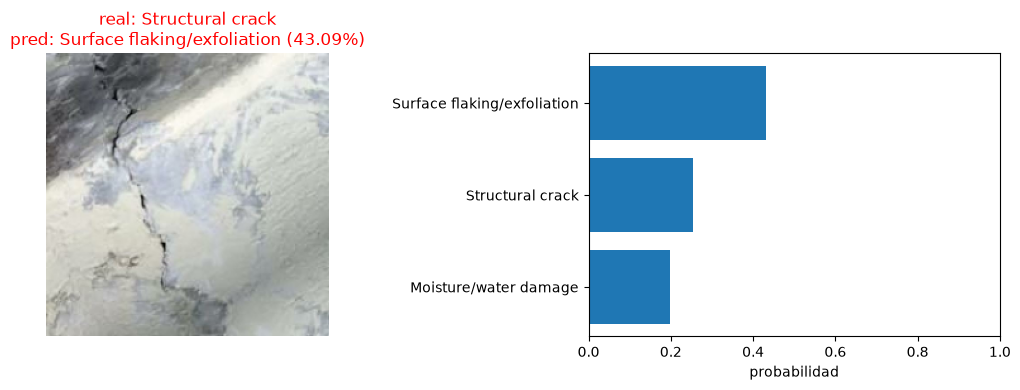

crack-1129-_jpg.rf.3b113657fe4d24d851fdc3dae9733def.jpg: Surface flaking/exfoliation (43.09%), Structural crack (25.28%), Moisture/water damage (19.69%)



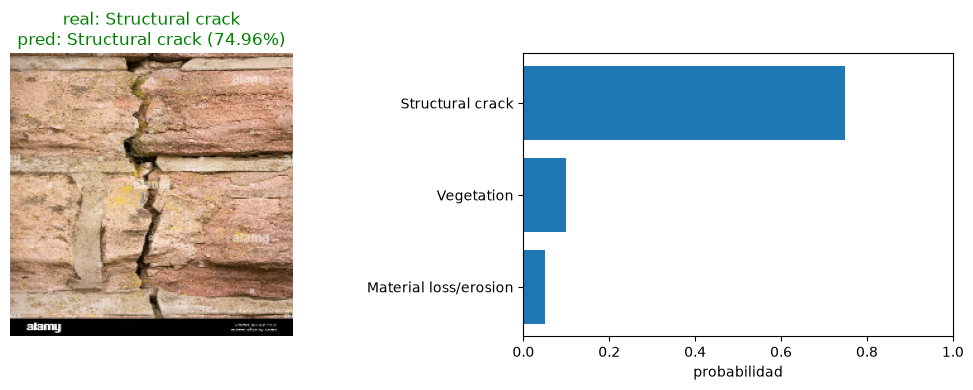

building-subsidence-large-crack-in-wall-of-stone-built-barn-conversion-B3FRN6_jpg.rf.735cccab53b5f56e97bbc1bd7bdecfac.jpg: Structural crack (74.96%), Vegetation (10.01%), Material loss/erosion (5.14%)



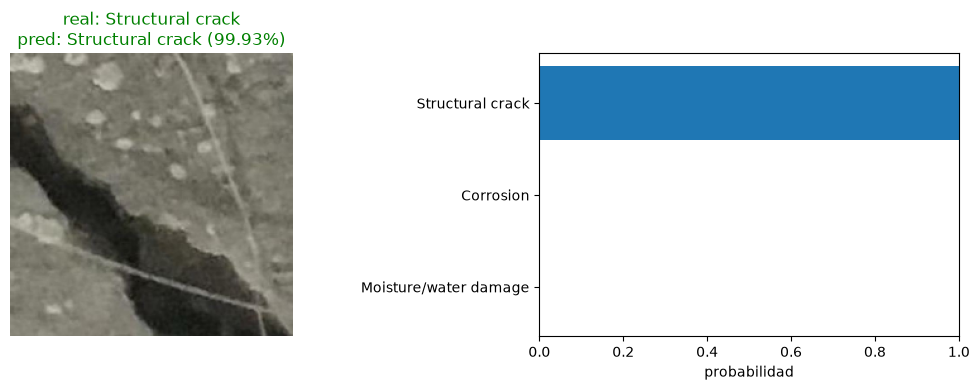

00159_jpg.rf.7877f65e7fb660e8bb6ab44200ac0900.jpg: Structural crack (99.93%), Corrosion (0.03%), Moisture/water damage (0.01%)



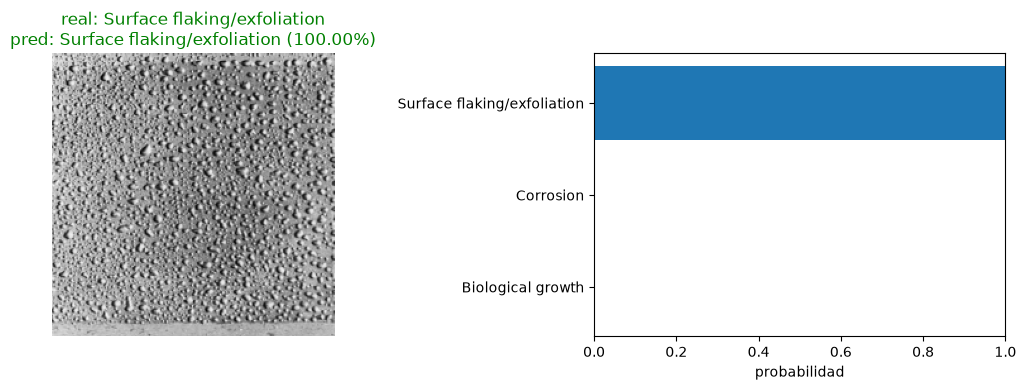

19_png_png_png_png_jpg.rf.21a59fec27ddddd09625914e8168ffcb.jpg: Surface flaking/exfoliation (100.00%), Corrosion (0.00%), Biological growth (0.00%)



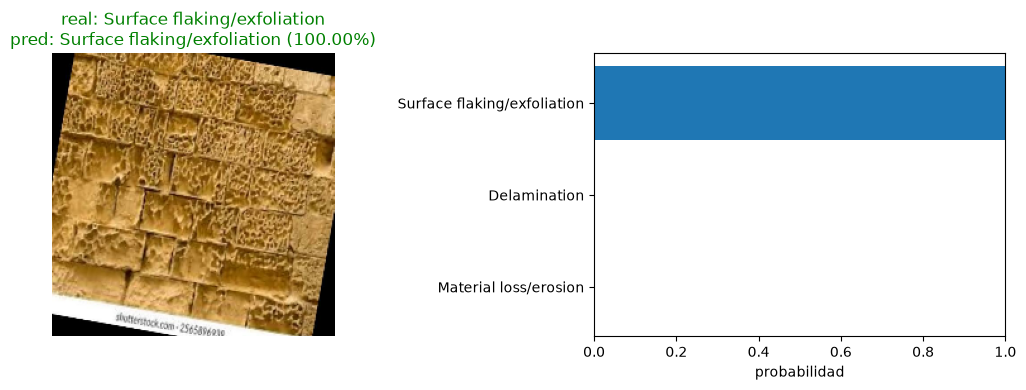

images-17-_jpg.rf.dc272cfffa5a0a40940368c0a72b3c6c.jpg: Surface flaking/exfoliation (100.00%), Delamination (0.00%), Material loss/erosion (0.00%)



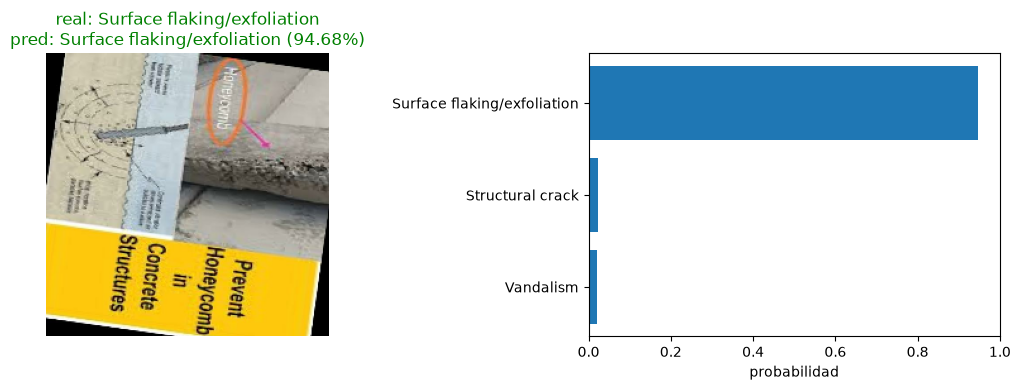

types-of-honeycomb-in-concrete_78_jpg.rf.362d4914091e623150f0b9f9d60c755c.jpg: Surface flaking/exfoliation (94.68%), Structural crack (2.19%), Vandalism (1.99%)



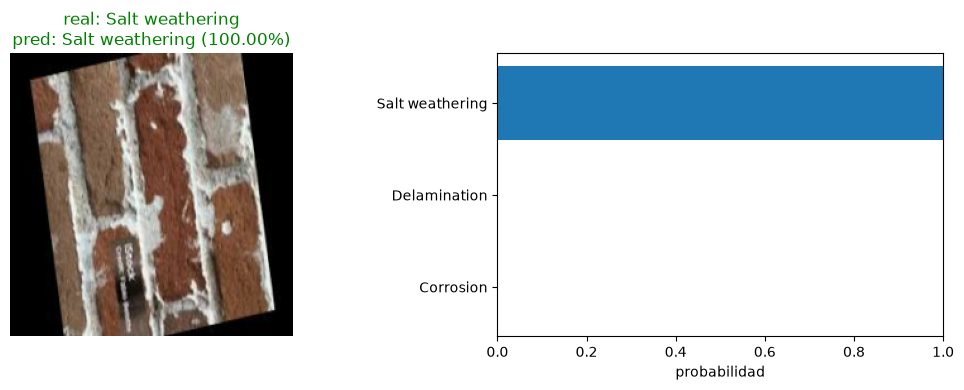

images-87-_jpg.rf.44560c8d73453f94df5de4a796bc6420.jpg: Salt weathering (100.00%), Delamination (0.00%), Corrosion (0.00%)



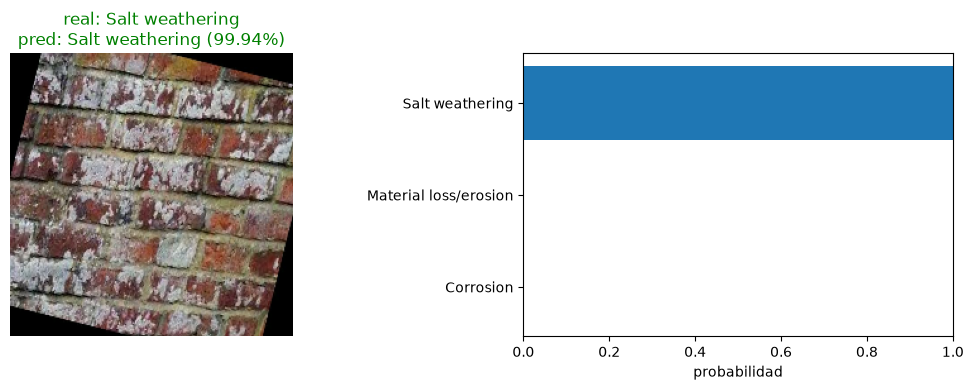

images-2026-04-02T151304-657_jpg.rf.d3832aa39ad07944aa9009d1cb5634dc.jpg: Salt weathering (99.94%), Material loss/erosion (0.06%), Corrosion (0.00%)



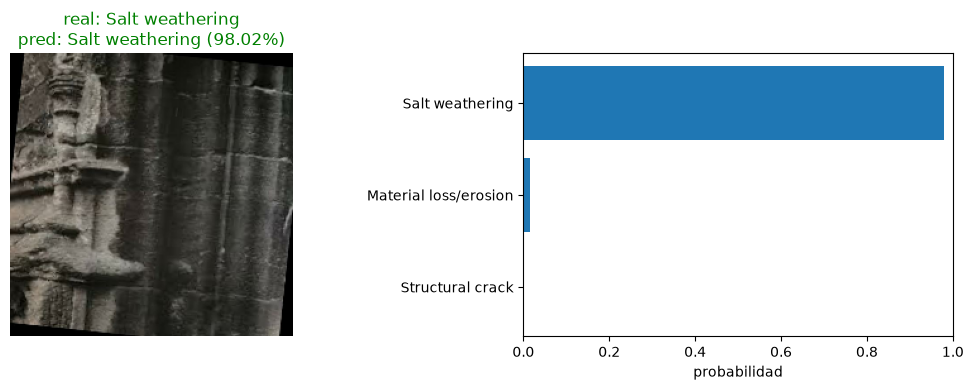

images-81-_jpg.rf.2ffc12e54d03ce9229db4cce9cf5edb5.jpg: Salt weathering (98.02%), Material loss/erosion (1.57%), Structural crack (0.10%)



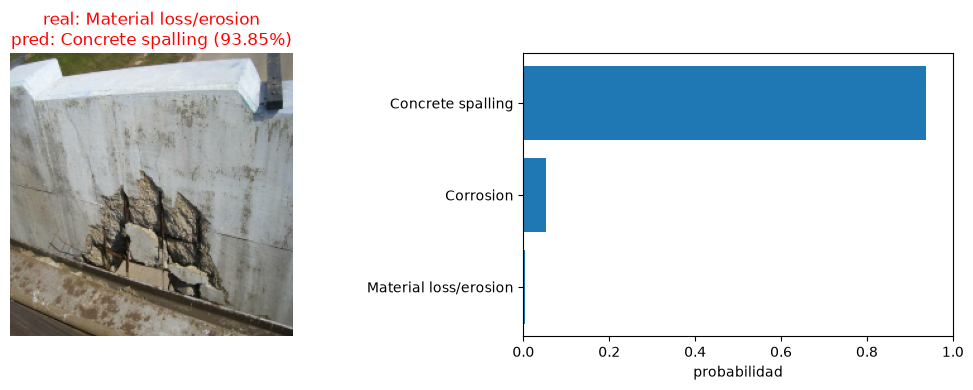

Image_-46-_jpg.rf.5ef2c1ebd01118c9bc54a2bcf6b7f464.jpg: Concrete spalling (93.85%), Corrosion (5.20%), Material loss/erosion (0.39%)



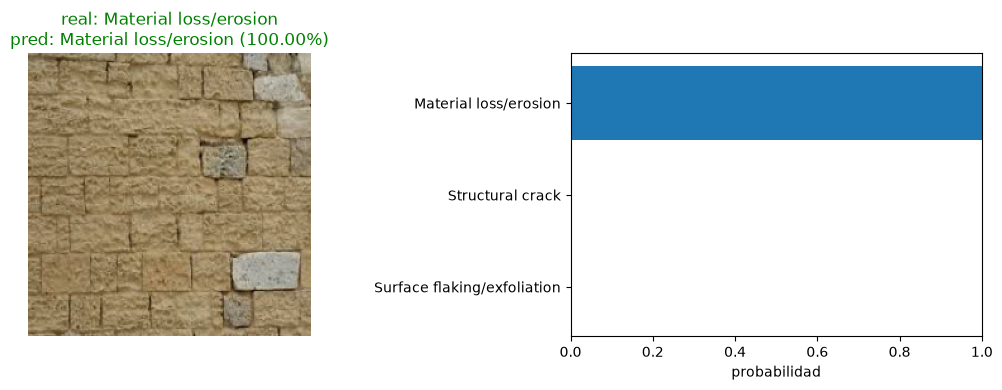

images-93-_jpg.rf.e331c466dfef943b446c422d64e6cf70.jpg: Material loss/erosion (100.00%), Structural crack (0.00%), Surface flaking/exfoliation (0.00%)



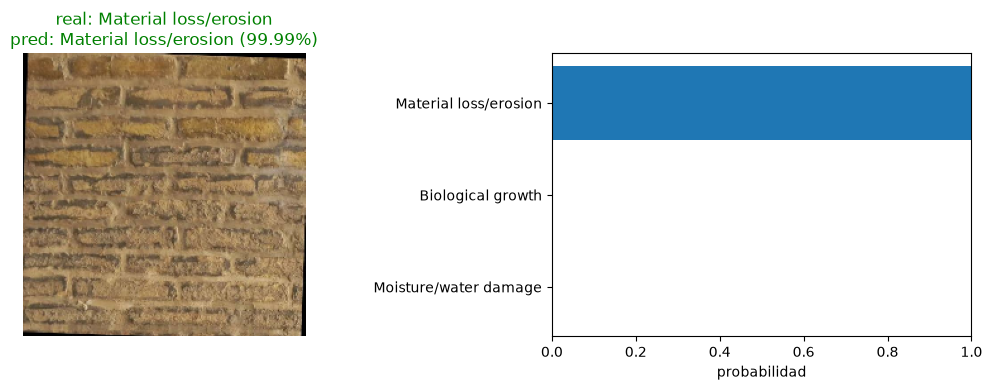

B_Erosin-441-_jpg.rf.aeeb35b35307d346b57dafdf1aad80d2.jpg: Material loss/erosion (99.99%), Biological growth (0.01%), Moisture/water damage (0.00%)



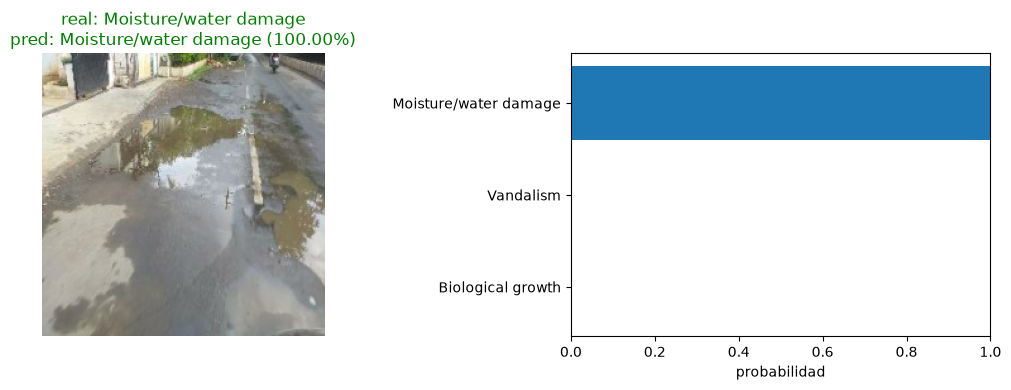

image202.jpeg: Moisture/water damage (100.00%), Vandalism (0.00%), Biological growth (0.00%)



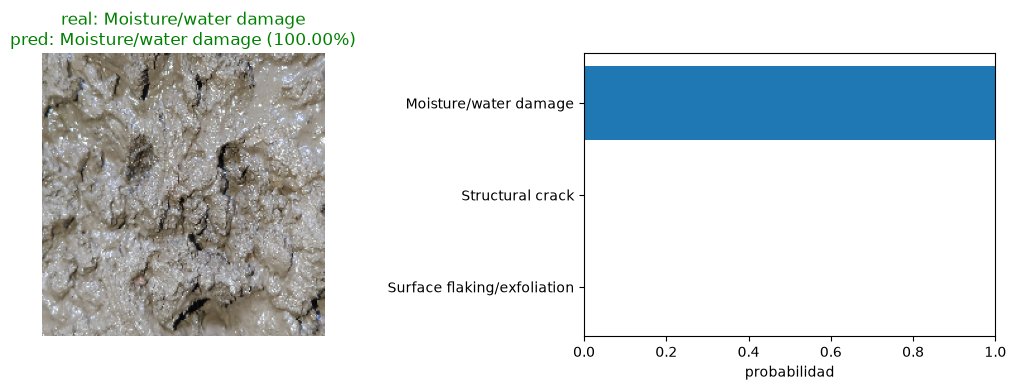

20250428_170138.JPG: Moisture/water damage (100.00%), Structural crack (0.00%), Surface flaking/exfoliation (0.00%)



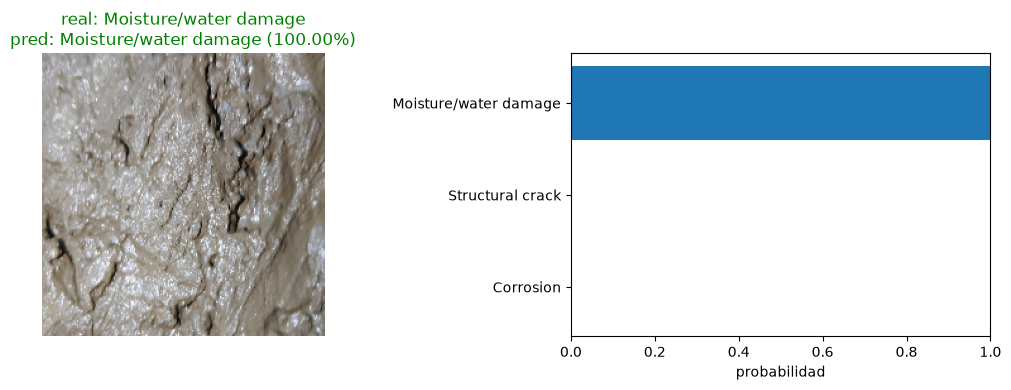

20250428_200007.JPG: Moisture/water damage (100.00%), Structural crack (0.00%), Corrosion (0.00%)



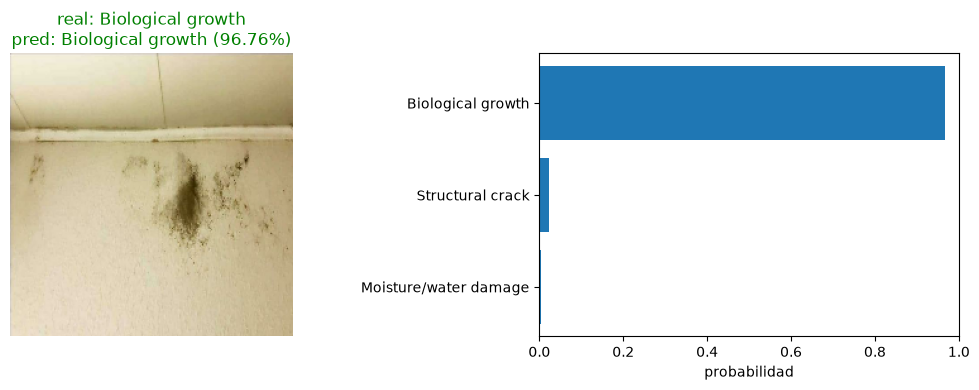

38-black-mold-on-ceiling-2-1_jpeg_jpg.rf.80498868d42142e452ba0c079f8f4944.jpg: Biological growth (96.76%), Structural crack (2.38%), Moisture/water damage (0.49%)



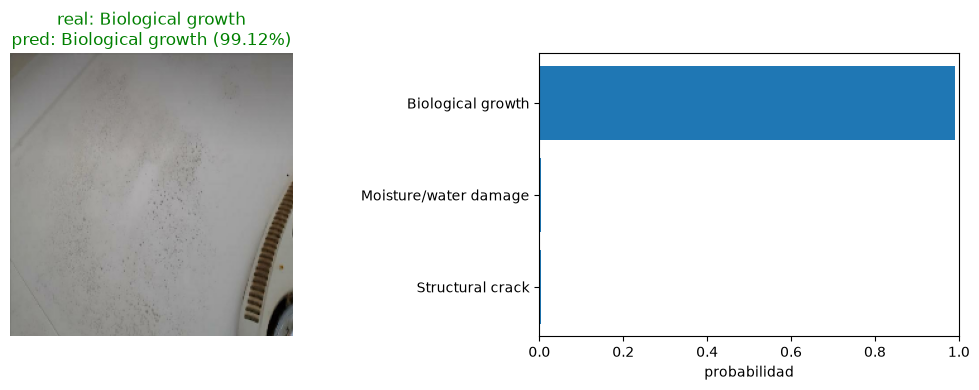

17-confirm-the-cause_jpg.rf.45b019590a722fb3efe35fffb64641c4.jpg: Biological growth (99.12%), Moisture/water damage (0.43%), Structural crack (0.41%)



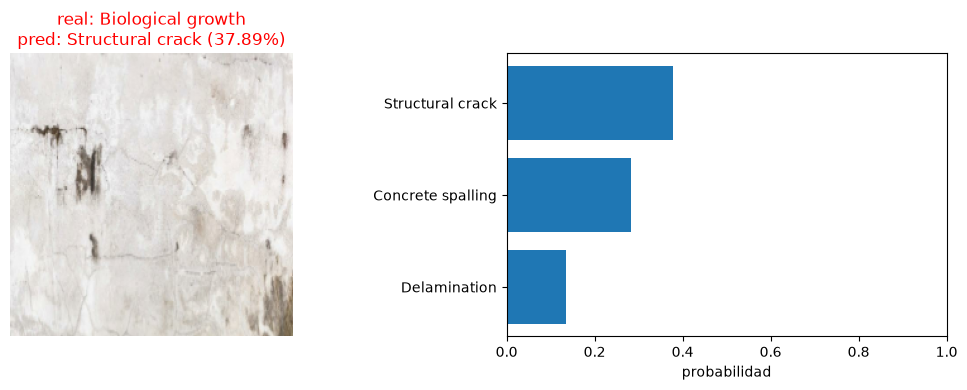

Img_498_png.rf.7a79af51b2fc3535da53add290f3b920.jpg: Structural crack (37.89%), Concrete spalling (28.36%), Delamination (13.55%)



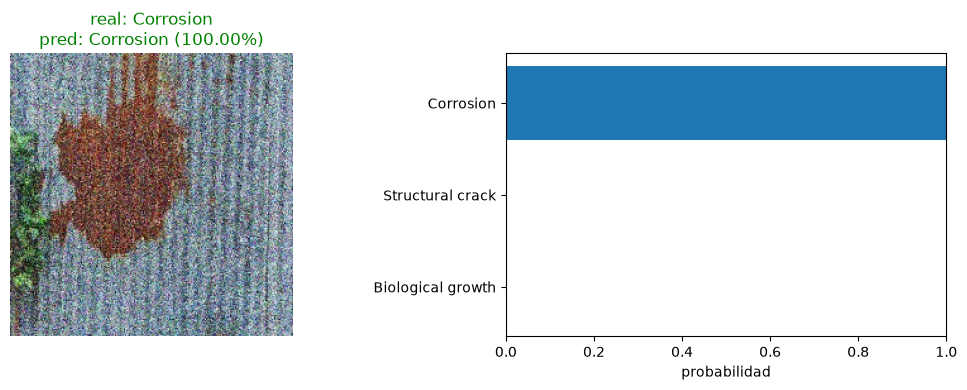

aug_17_1743130479436_M10_jpg.rf.2c685f21c1f086796638518f54a6d424.jpg: Corrosion (100.00%), Structural crack (0.00%), Biological growth (0.00%)



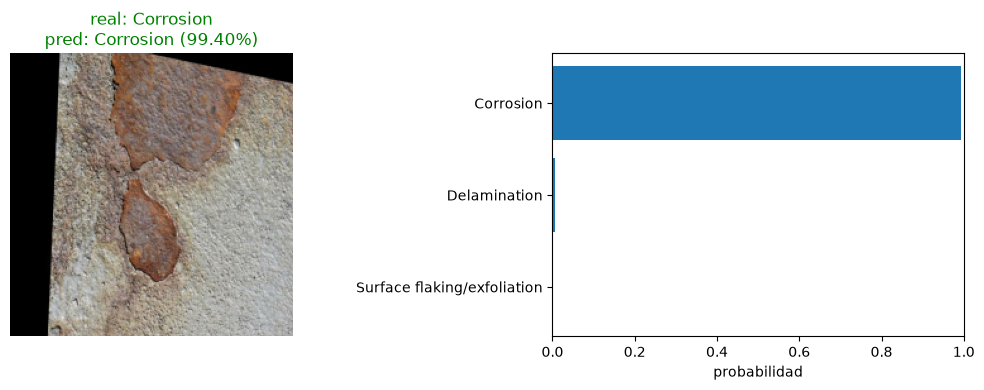

aug_15_1743130422980_11_jpg.rf.09f6968bca014f63aedfa5a4cf8bbe51.jpg: Corrosion (99.40%), Delamination (0.59%), Surface flaking/exfoliation (0.01%)



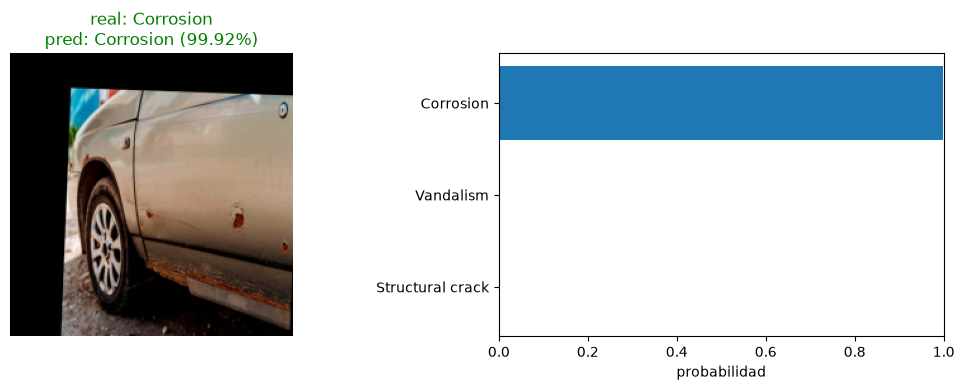

aug_8_1743130441834_9aa3041824_jpg.rf.6254148861b8978a30ab20f747054b72.jpg: Corrosion (99.92%), Vandalism (0.06%), Structural crack (0.01%)



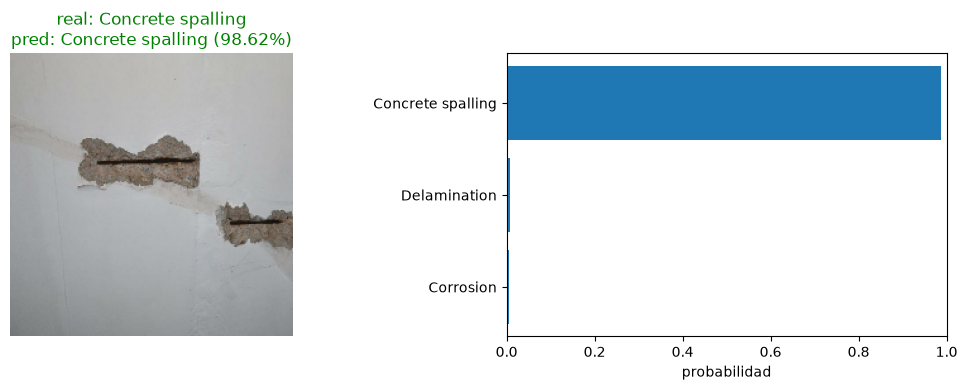

001559_jpg.rf.0be2ecc4a00a71b895fbc4a37146010f.jpg: Concrete spalling (98.62%), Delamination (0.80%), Corrosion (0.56%)



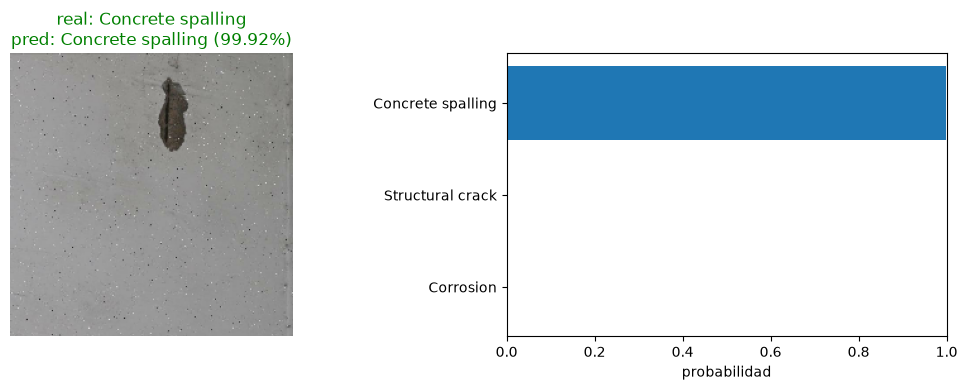

00928_jpg.rf.c89eda20d0adbb8f82f2e155f0760149.jpg: Concrete spalling (99.92%), Structural crack (0.07%), Corrosion (0.01%)



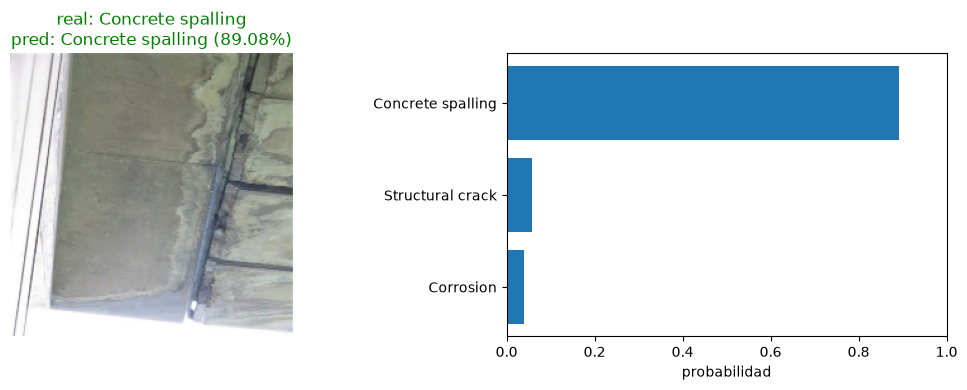

-814-_jpg.rf.26f5f49324b4f74f6b2328e6ef56950e.jpg: Concrete spalling (89.08%), Structural crack (5.69%), Corrosion (3.95%)



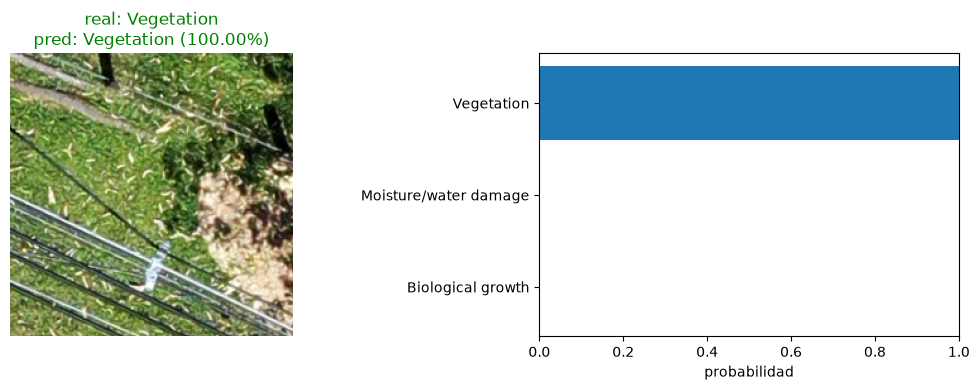

175.png: Vegetation (100.00%), Moisture/water damage (0.00%), Biological growth (0.00%)



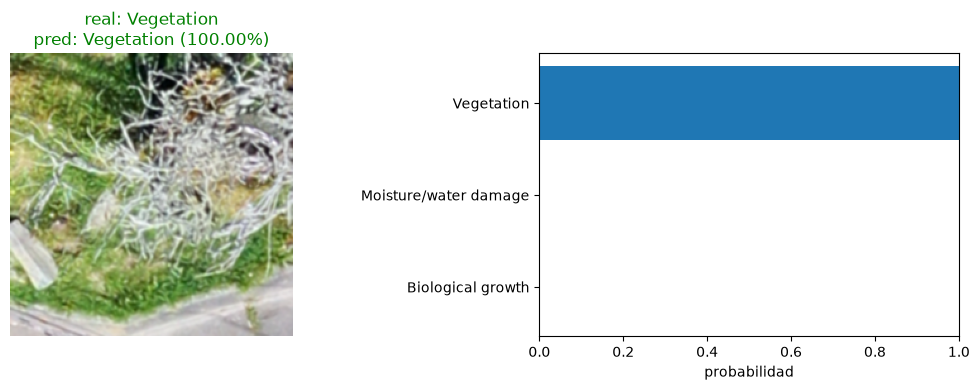

154_3.png: Vegetation (100.00%), Moisture/water damage (0.00%), Biological growth (0.00%)



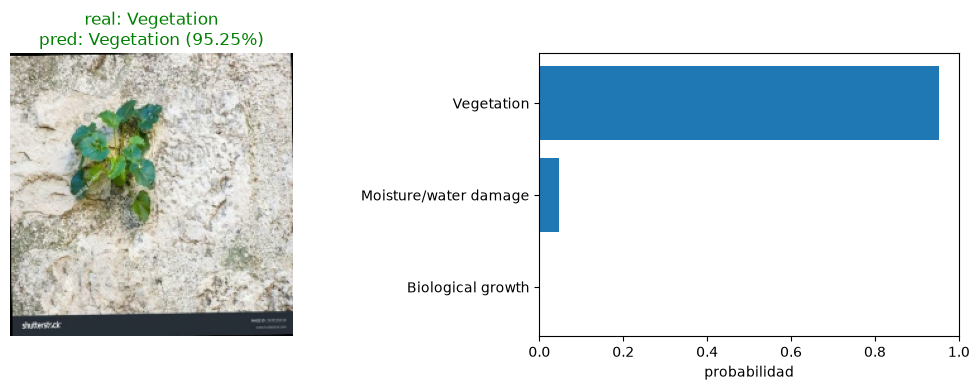

stock-photo-green-plant-growing-in-rock-weed-in-stone-wall-crack-2439195519_jpg.rf.bbda11e53831cb5feb9bc652a438886f.jpg: Vegetation (95.25%), Moisture/water damage (4.74%), Biological growth (0.00%)



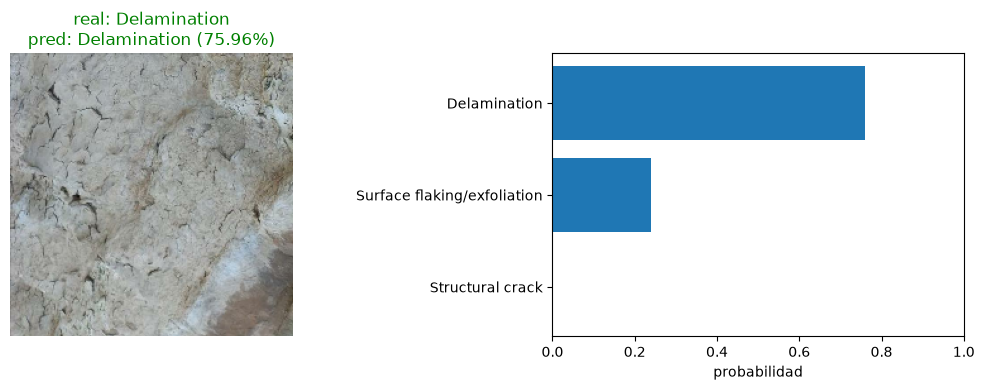

S_Flaking451_jpg.rf.1552134e5d7b6c5fed7cdf745421f786.jpg: Delamination (75.96%), Surface flaking/exfoliation (23.99%), Structural crack (0.02%)



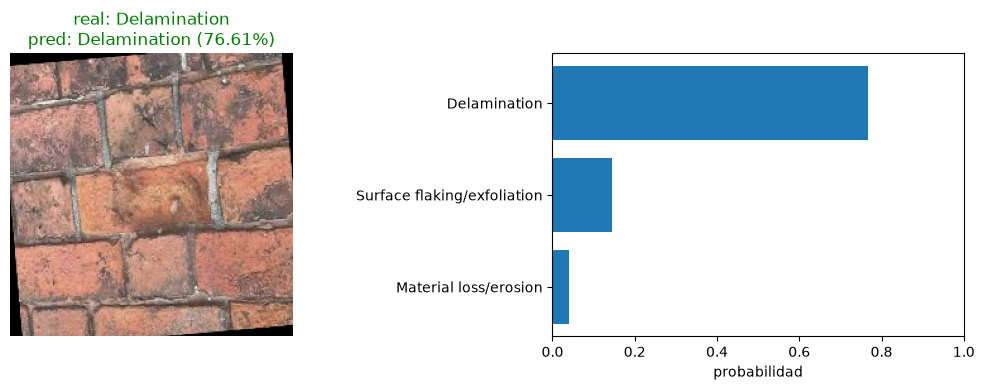

images-2026-03-30T203149-544_jpg.rf.29c1adbb46067af6b557e0bb81f4791f.jpg: Delamination (76.61%), Surface flaking/exfoliation (14.58%), Material loss/erosion (4.12%)



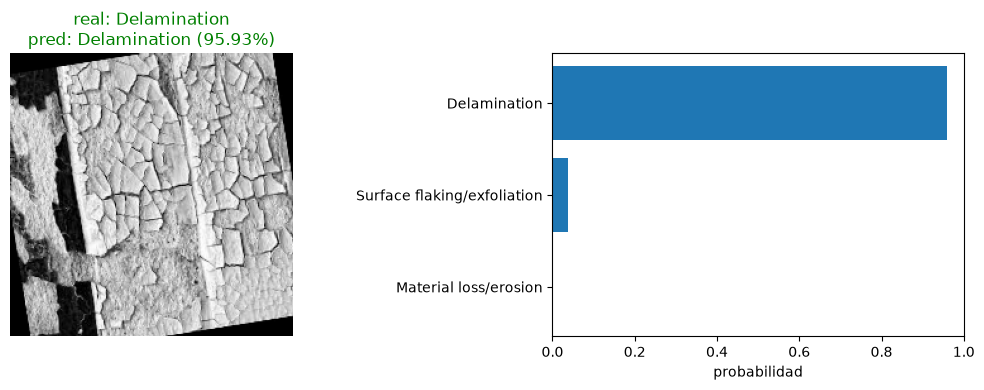

images-2026-03-30T203149-549_jpg.rf.d9155cc98504617f56162b147a67e2d0.jpg: Delamination (95.93%), Surface flaking/exfoliation (3.89%), Material loss/erosion (0.14%)



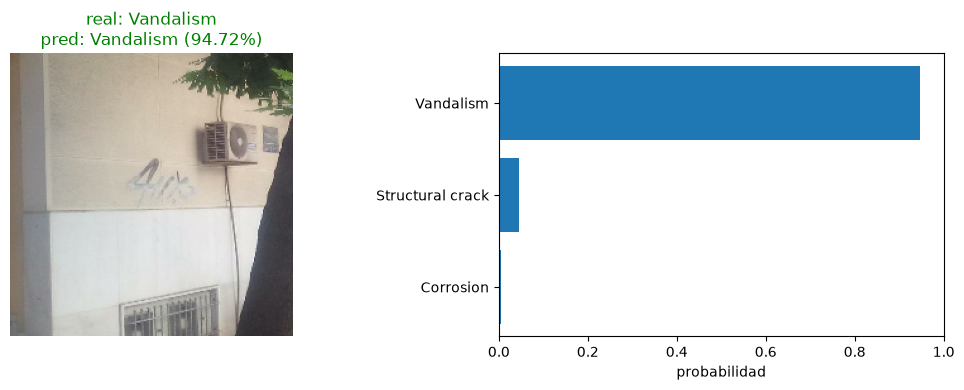

IMG_20180810_093055_jpg.rf.9633eee97223f71dab27a494f08d8fa2.jpg: Vandalism (94.72%), Structural crack (4.62%), Corrosion (0.54%)



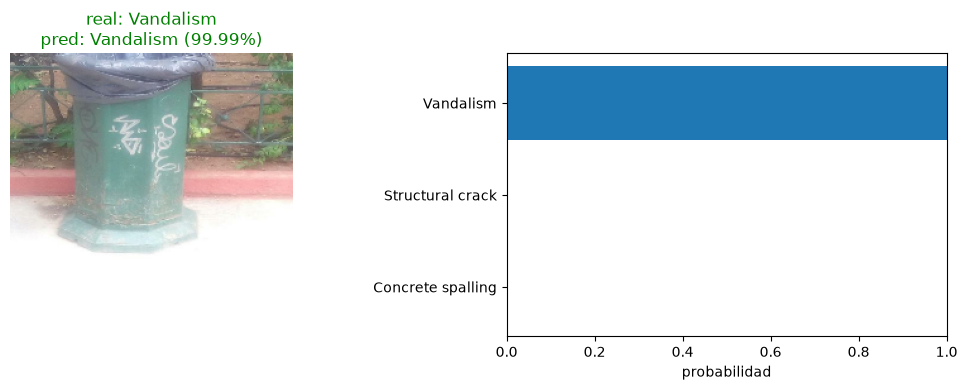

IMG_20100101_033559_jpg.rf.7c9165cb256082e5f6d1e6d92934f5a5.jpg: Vandalism (99.99%), Structural crack (0.01%), Concrete spalling (0.00%)



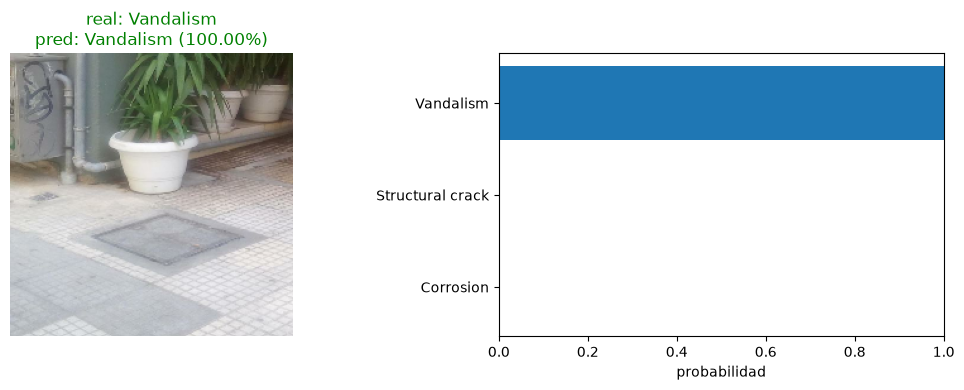

IMG_20180717_122646_jpg.rf.e14078f92c5abc51c450c94a7056b8f3.jpg: Vandalism (100.00%), Structural crack (0.00%), Corrosion (0.00%)

Acerto 30 de 33 (91%)


In [6]:
# Celda 6: prediccion
# Para cada imagen muestra la foto con la clase predicha en el titulo
# (y la real si se conoce: verde si acerto, rojo si no) y al lado el
# grafico de barras de las TOP_K clases mas probables. Si hay clase real,
# al final imprime cuantas acerto.
# Depende de: predecir_dano (celda 4), a_probar (celda 5), TOP_K (celda 2)

aciertos = 0
for ruta, real in zip(a_probar["image_path"], a_probar["label"]):
    img, ranking = predecir_dano(ruta)
    clase, prob = ranking[0]
    top = ranking[:TOP_K]

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.2, 1]})
    ax_img.imshow(img.numpy().astype("uint8"))
    ax_img.axis("off")
    if real is None:
        ax_img.set_title(f"{os.path.basename(ruta)}\npred: {clase} ({prob:.2%})")
    else:
        aciertos += clase == real
        color = "green" if clase == real else "red"
        ax_img.set_title(f"real: {real}\npred: {clase} ({prob:.2%})", color=color)

    ax_bar.barh([c for c, _ in top][::-1], [p for _, p in top][::-1])
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel("probabilidad")
    plt.tight_layout()
    plt.show()

    print(f"{os.path.basename(ruta)}: " + ", ".join(f"{c} ({p:.2%})" for c, p in top) + "\n")

if a_probar["label"].notna().all():
    print(f"Acerto {aciertos} de {len(a_probar)} ({aciertos / len(a_probar):.0%})")